In [27]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("bayesian_stats_course_tools.light")
import scipy.stats
import emcee
from pathlib import Path
from emcee.autocorr import integrated_time
from scipy.signal import lfilter
import arviz

#plt.rcParams['text.usetex'] = True # comment out if you don't have latex installed. May cause errors downstream in titles, etc.
figdir = Path('./')
savefigs = True

# Exercise 1: Autocorrelation

## Intro material

In [28]:
Nsamples = 4000
# Gaussian random samples
iid_samples = np.random.randn(Nsamples)

### Create correlated samples

The (normalized) autocorrelation function is given by:

$$\rho(|t_i - t_j|) = e^{{-2|t_i - t_j| / \tau}}$$

where $\tau$ here is the $\tau$ we defined in the lecture notes. Below, we generate correlated samples with this autocorrelation function. There are a few ways to do this; I've taken a shortcut with an "autoregressive" model to make the generation of fake data fast. Use this code as a blackbox for now to generate correleted samples:
```python
tau_autocorr = 10


def ar1(N, tau, rng):
    phi = np.exp(-2/tau)
    w = rng.standard_normal(N)
    w[0] /= np.sqrt(1 - phi**2)          # stationary start
    return lfilter([np.sqrt(1 - phi**2)], [1, -phi], w)

correlated_samples = ar1(Nsamples, tau_autocorr, rng)
```

In [29]:
tau_autocorr = 10



rng = np.random.default_rng(0)

# auto-regressive process to produce correlated samples
# according to an exponential autocorrelation function
# this is much faster than creating a toepliz covariance matrix
# with rho = exp(-2 * lag / tau) and using np.random.multivariate_normal
def ar1(N, tau, rng, nchains=1):
    phi = np.exp(-2/tau)
    w = rng.standard_normal((N, nchains))
    w[0] /= np.sqrt(1 - phi**2)          # stationary start
    return lfilter([np.sqrt(1 - phi**2)], [1, -phi], w, axis=0)

correlated_samples = ar1(Nsamples, tau_autocorr, rng)

tau_estimated = emcee.autocorr.integrated_time(correlated_samples)
print(f'estimated tau: {tau_estimated}, true tau: {tau_autocorr}')

estimated tau: [11.46087968], true tau: 10


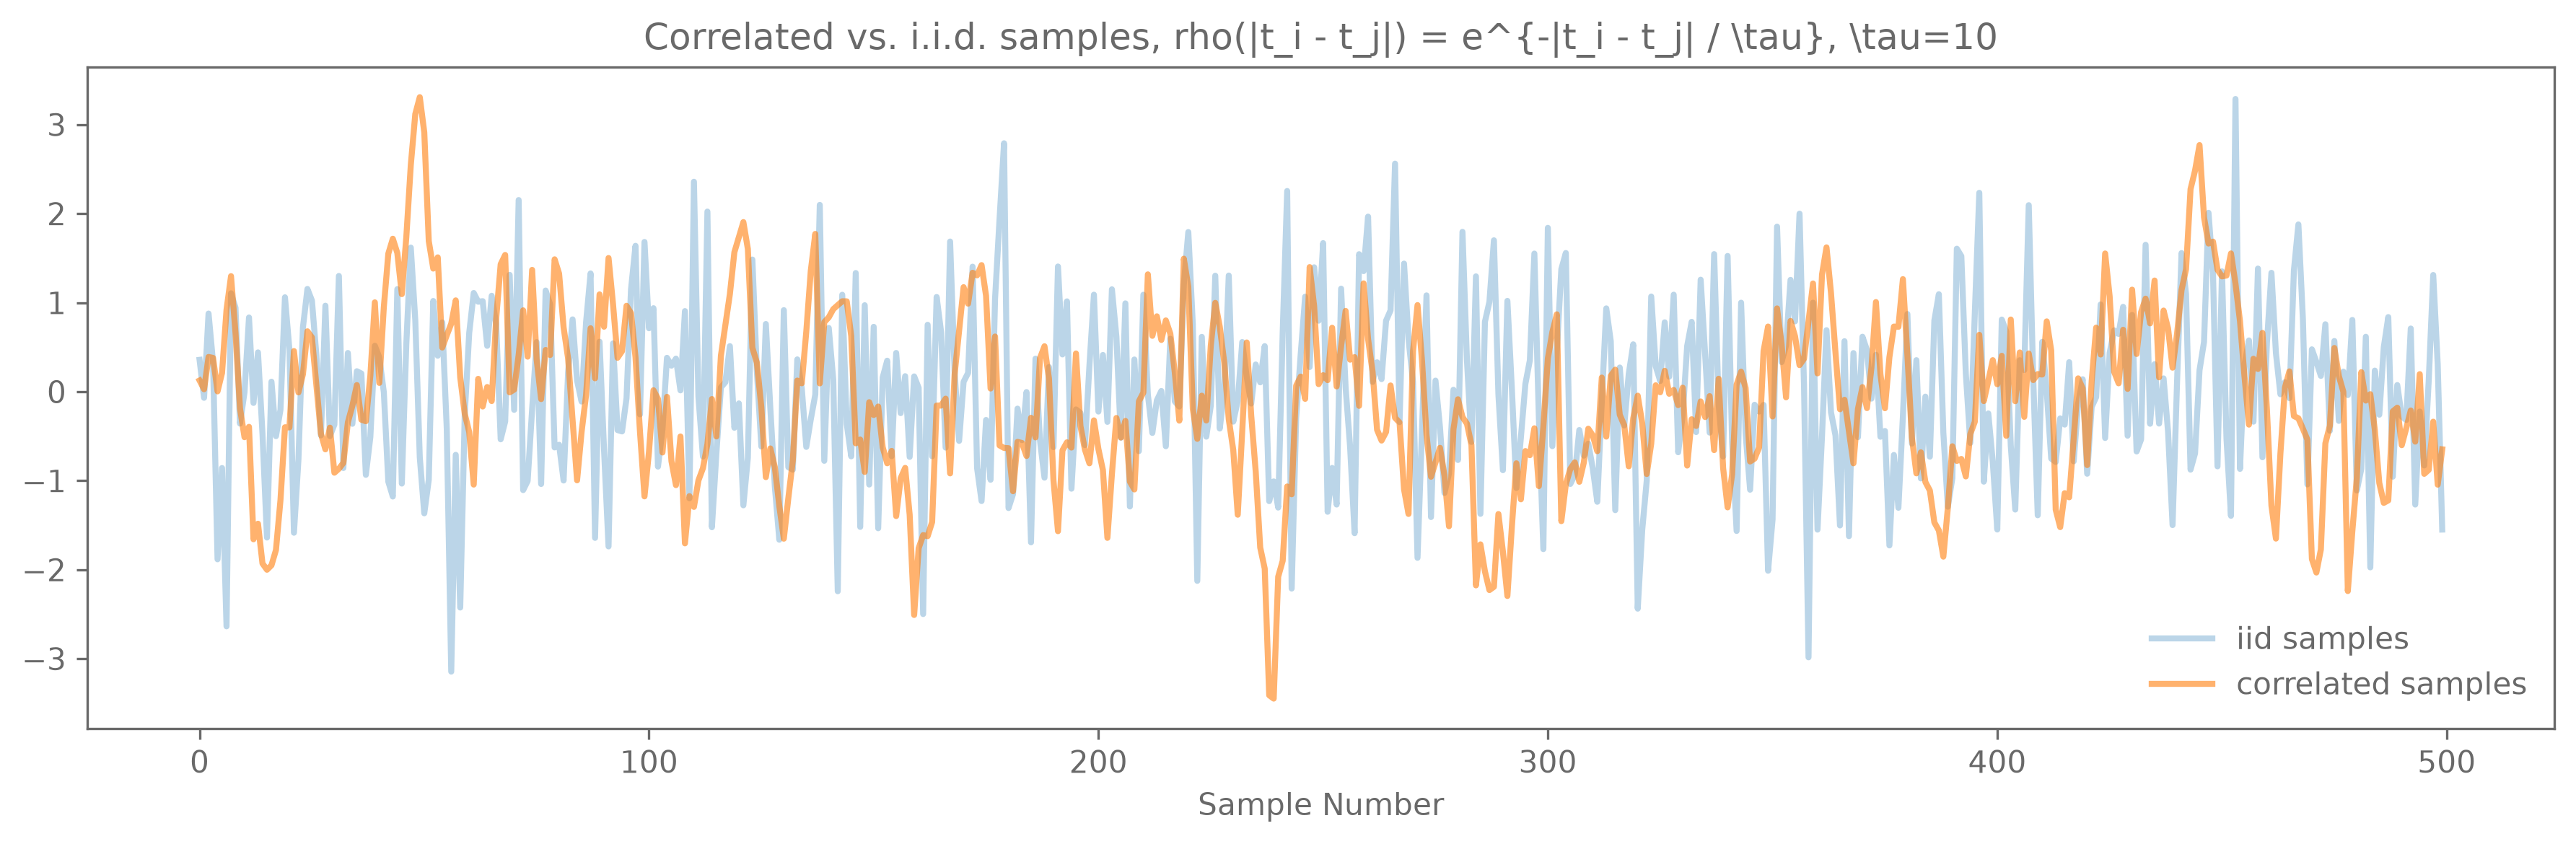

In [30]:
plt.figure(figsize=(12, 4))
# may cause an error if you don't have latex installed. Can comment out title in that case.
plt.title(f"Correlated vs. i.i.d. samples, rho(|t_i - t_j|) = e^{{-|t_i - t_j| / \\tau}}, \\tau={tau_autocorr}")
plt.plot(iid_samples[:tau_autocorr*50], lw=2, label='iid samples', alpha=0.3)
plt.plot(correlated_samples[:tau_autocorr*50], lw=2, label='correlated samples', alpha=0.6)
plt.legend()
plt.xlabel("Sample Number")
plt.tight_layout()
if savefigs:
    plt.savefig(figdir / "correlated_samples_example.pdf")
plt.show()

### Gelman Rubin calculator

In [31]:
def gelman_rubin(x):
    n, m = x.shape
    chain_means = x.mean(axis=0)
    chain_vars = x.var(axis=0, ddof=1)

    # mean of variances
    W = chain_vars.mean()

    # variances of means
    B = n * chain_means.var(ddof=1)

    # construct the statistic
    var_hat = (n - 1) / n * W + B / n
    return np.sqrt(var_hat / W)

# split our chain up into 10 separate chains
split_chains = 10
print('Rhat statistic:', gelman_rubin(iid_samples.reshape((split_chains, Nsamples // split_chains)).T))

# NOTE: Do not pass emcee chains that come from different walkers and calculate an Rhat on that -- those chains are correlated with each other
# and you will not get a good estimate of convergence. This is mentioned here: https://emcee.readthedocs.io/en/stable/tutorials/autocorr/

Rhat statistic: 0.9994012642354541


### Look at autocorrelation times

In [32]:
import matplotlib.pyplot as plt

In [33]:
# estimate autocorrelation times using emcee's method many times for many
# realizations. look at variance of this quantity. 
taus = [integrated_time(ar1(Nsamples, tau_autocorr, rng), quiet=True, tol=0)[0] for _ in range(1000)]

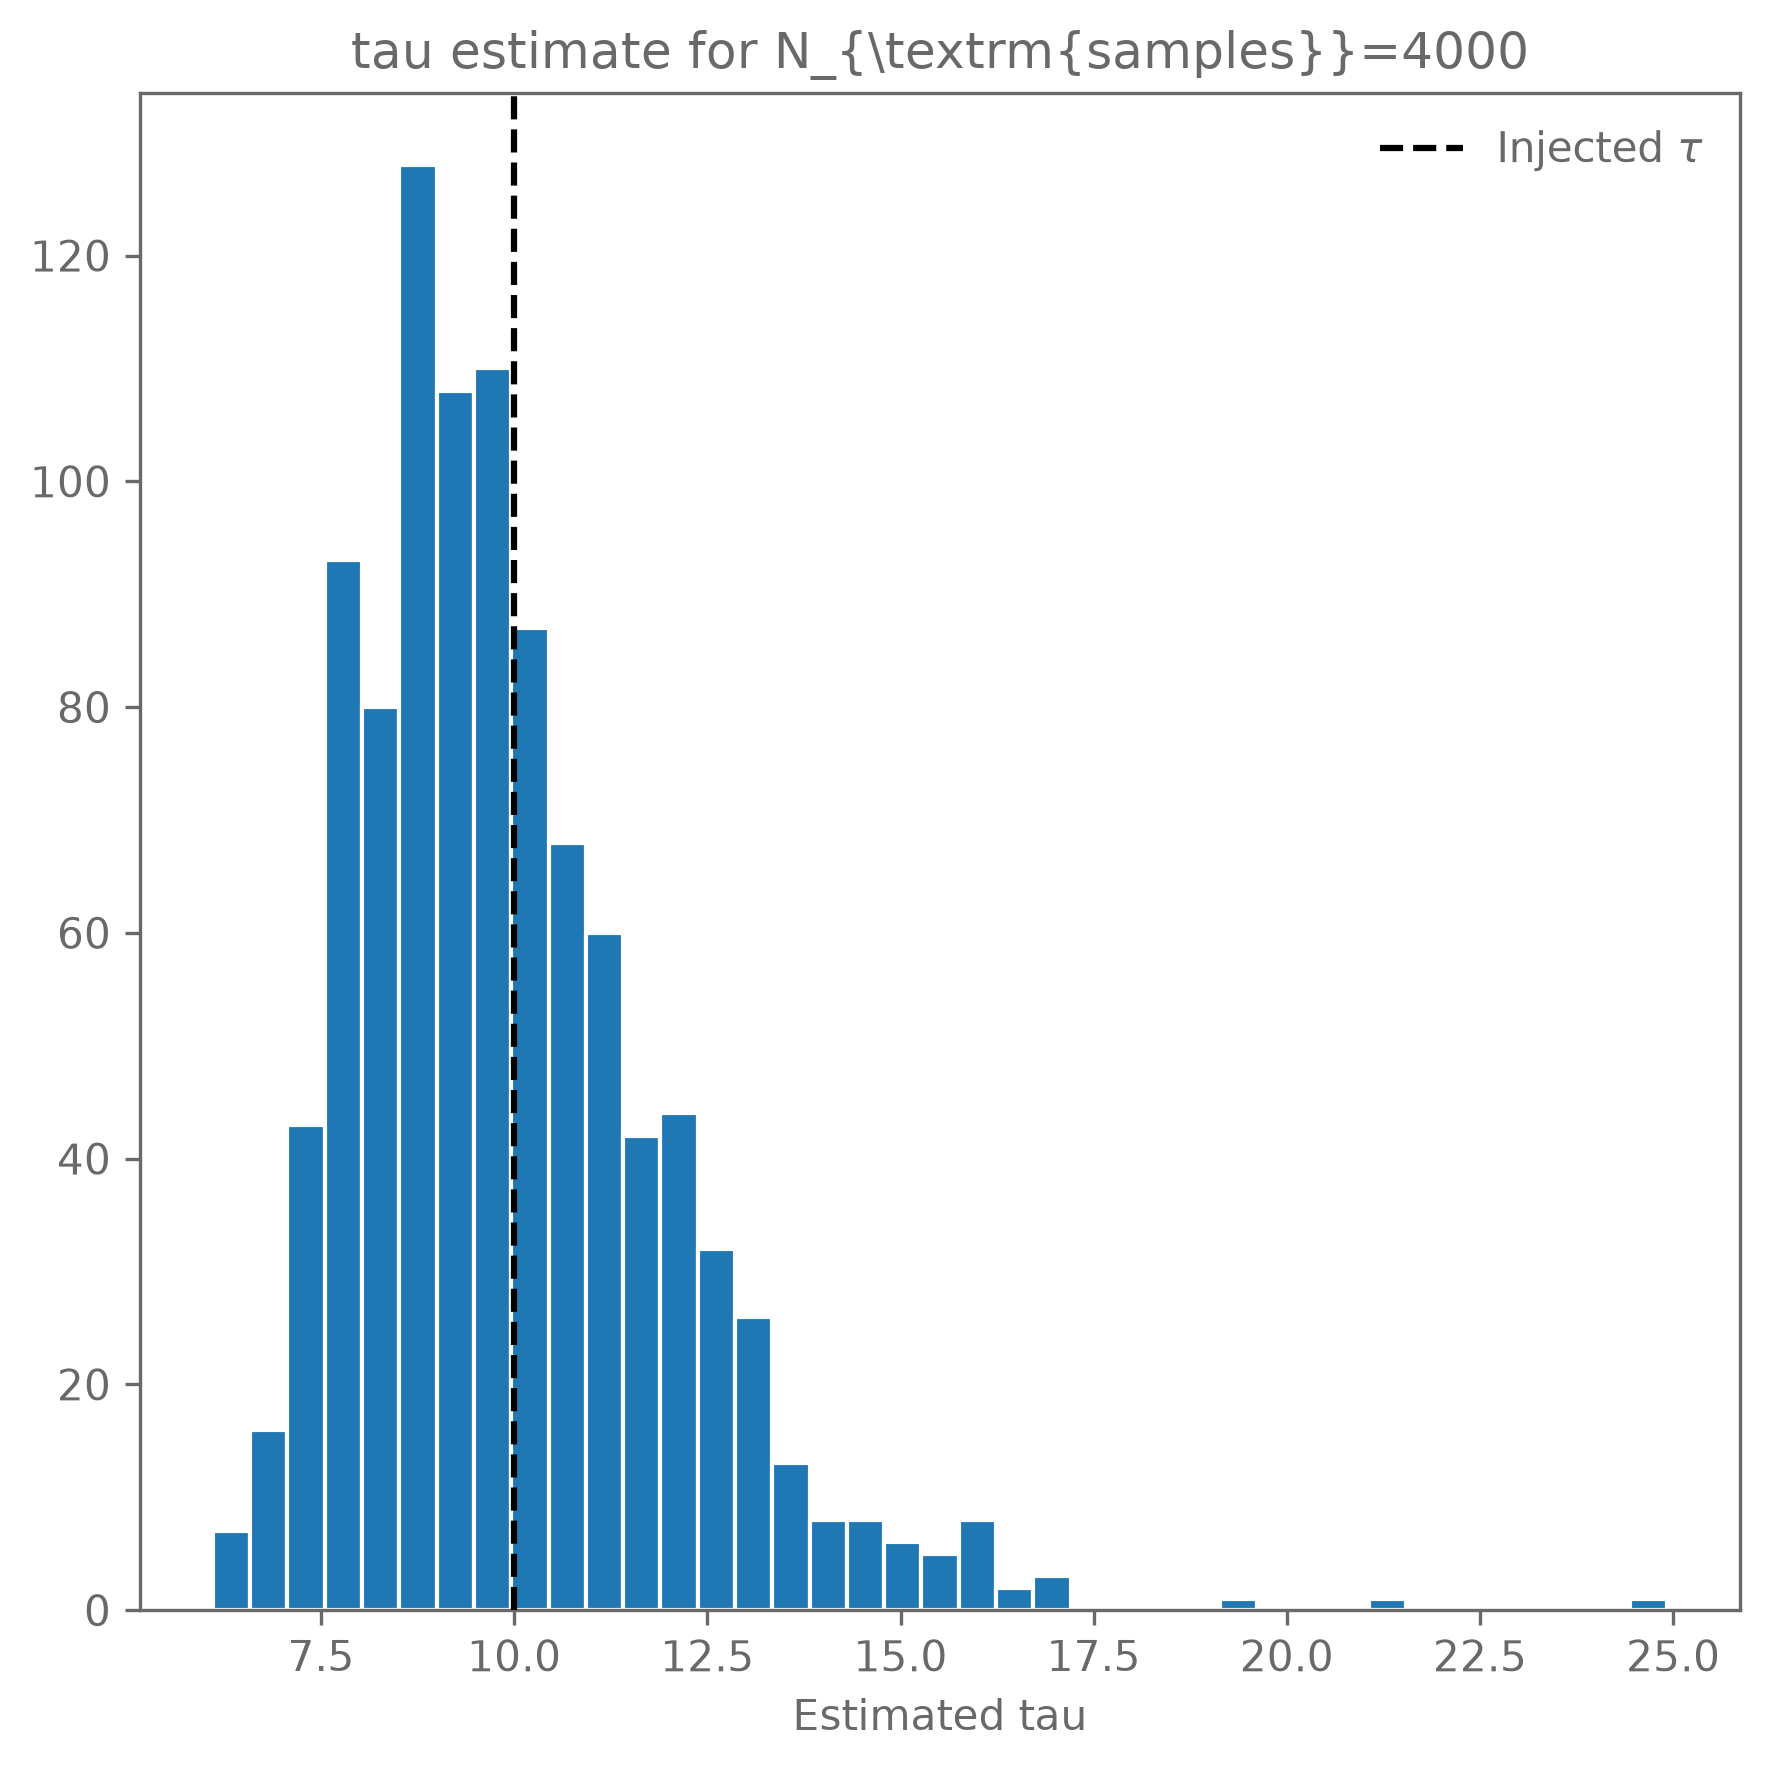

In [34]:
plt.figure(figsize=(6, 6))
plt.hist(taus, bins='auto', edgecolor='w')
ax = plt.gca()
ax.axvline(tau_autocorr, c='k', ls='--', zorder=100, label='Injected $\\tau$')
plt.xlabel("Estimated tau")
plt.title(f'tau estimate for N_{{\\textrm{{samples}}}}={Nsamples}')
plt.legend()
plt.tight_layout()
if savefigs:
    plt.savefig(figdir / "tau_estimates.pdf")
plt.show()

## Exercise 1: Problem statement

* For a given $N_{samples}$ create many simulated chains with both correlated and iid samples.
* * For each chain, look at the mean.
* **How does *the variance of the means* compare between the correlated and iid samples? Repeat this again for different $N_{samples}$.**
* **How do these variances scale with $N_{samples}$? What about $n_{eff}$?**

Use the `ar1(N, rng, nchains=1)` function, defined above, to simulate data, where "N" is the number of samples per chain, "rng" is the random number generator from above, and "nchains" gives you the total number of chains to simulate of that length.

**important** when calling `integrated_time` make sure to use `quiet=True` and `tol=0` otherwise you may get a ton of error messages. 

In [35]:
N = 1000
nchains = 5
Nsamples_correlated = ar1(N,tau=tau_autocorr, rng=rng, nchains=nchains)
Nsamples_iid = ar1(N,tau=1, rng=rng,nchains=nchains)

N_mean_cor = np.empty(nchains)
N_mean_iid = np.empty(nchains)

N_var_cor = np.empty(nchains)
N_var_iid = np.empty(nchains)

for i in range(nchains):
    N_mean_cor[i] = np.mean(Nsamples_correlated[:,i])
    N_mean_iid[i] = np.mean(Nsamples_iid[:,i])
    


print(N_mean_cor)
print(N_mean_iid)

[-0.2298166   0.08829679  0.00296366  0.00459873 -0.06871224]
[-0.01777768  0.04651421  0.03570034 -0.01690557  0.01040973]


# Exercise 2 -- confidence intervals

## Calculate the 90% equal tail interval on the iid samples

## Use arviz to calculate a highest density interval

Use [arviz.hdi](https://python.arviz.org/en/v0.19.0/api/generated/arviz.hdi.html)

## Repeat for a multi-modal distribution
`hdi_bimodal = arviz.hdi(bimodal_samples, prob=.90,max_modes=2, method='multimodal')`
where you create the bimodal samples yourself. 

## Compare hdi and equal tail for the uni-modal and bimodal cases (make a plot)

# Exercise 3 -- $\chi^2$

## Intro material: an example first

In [36]:
from bayesian_stats_course_tools.analyse import plot_data, analyse_data

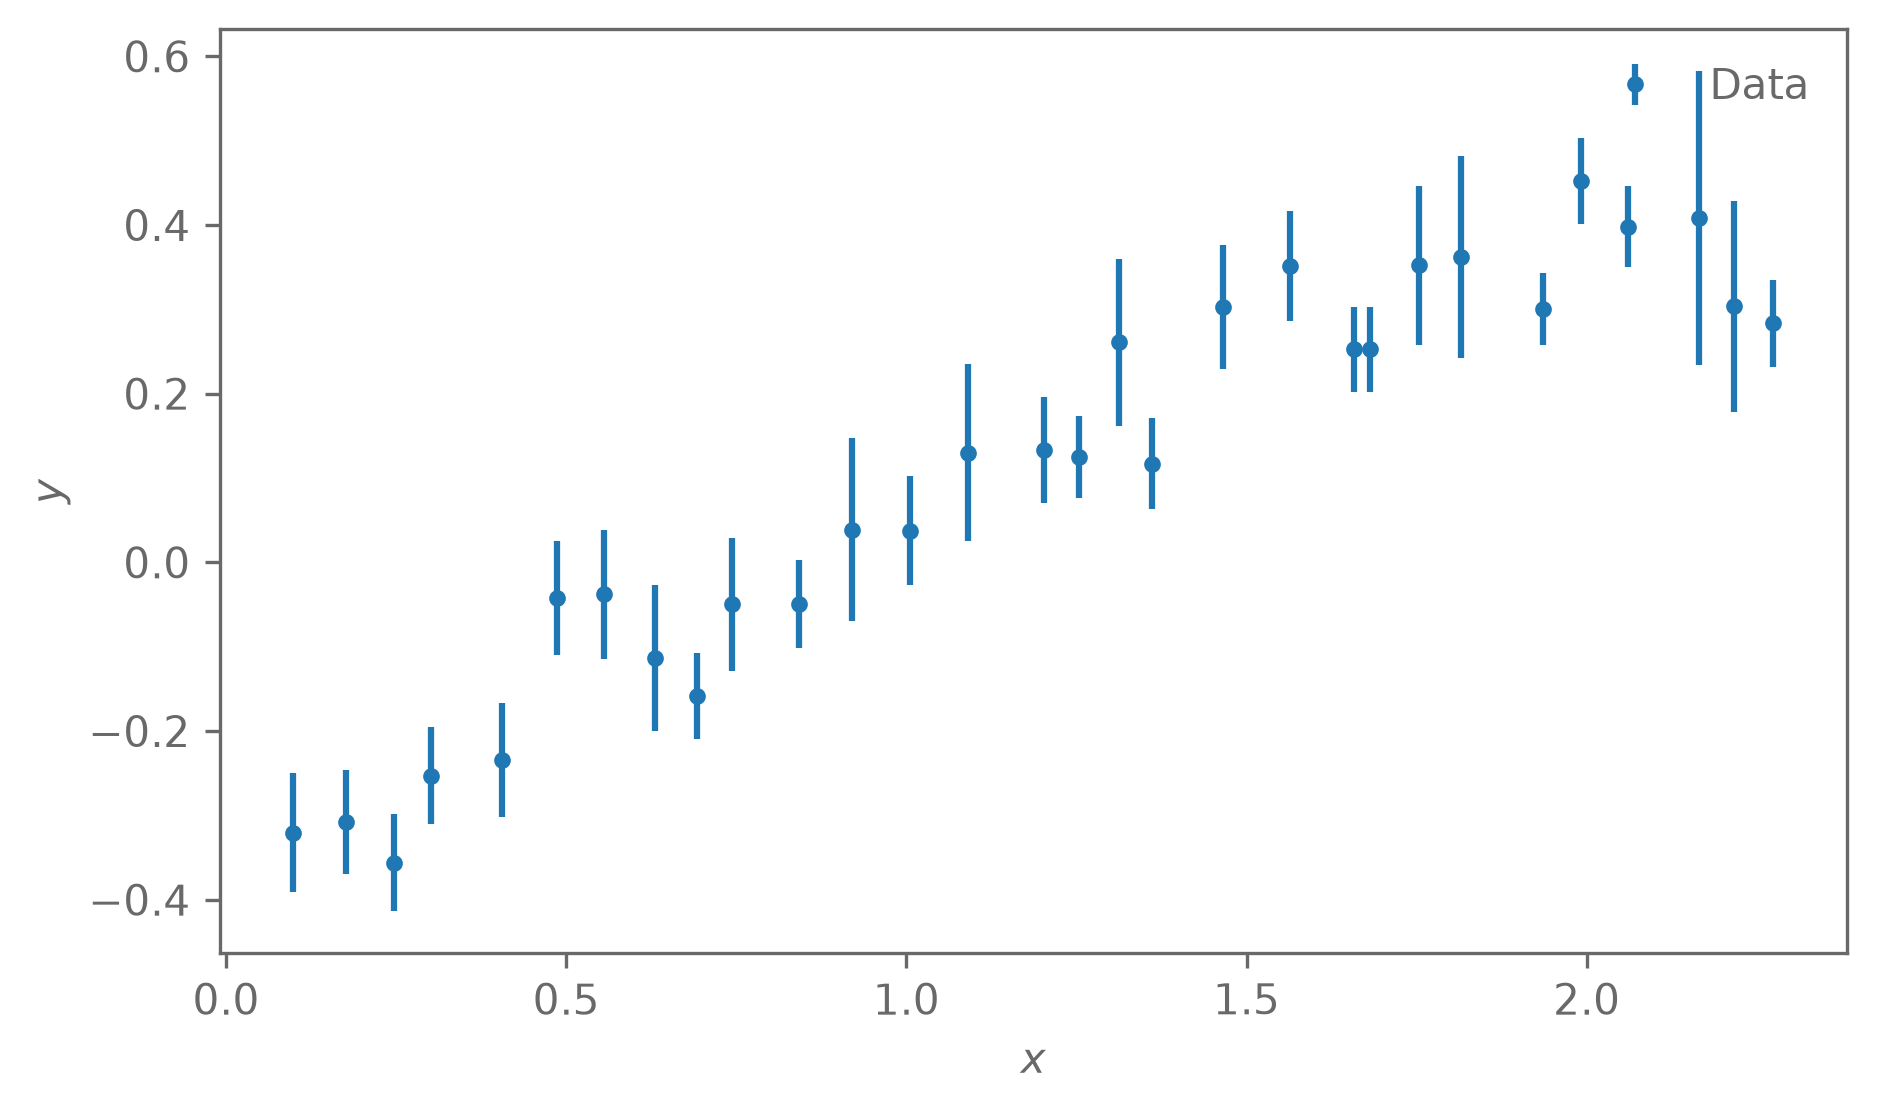

In [37]:
# let's load our data
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_2.txt", unpack=True)
a_true, b_true, c_true,  = -0.15, 0.7, -0.45

plot_data(x, y, y_err, );

### Gaussian likelihood, define models, etc. 

In [38]:
def make_gaussian_likelihood_components(model, log_prior):
    """Create the log_likelihood, log_posterior, predict functions from a
    model and log_prior"""
    def log_likelihood(y, theta, x, sigma_y):
        # the gaussian likelihood

        # 
        prediction = model(theta, x)

        return (
            -0.5 * np.sum((y - prediction)**2/sigma_y**2)    # Exponent
            -0.5 * np.sum(np.log(2*np.pi*sigma_y**2))        # Normalisation
        )
    
    def log_posterior(theta, x, sigma_y, y):
        # the full posterior is likelihood + prior
        return log_likelihood(y, theta, x, sigma_y) + log_prior(theta)
    
    def predict(theta, x, sigma_y):
        # for posterior predictive tests
        mu = model(theta, x)
        return np.random.normal(loc=mu, scale=sigma_y)
    
    return log_likelihood, log_posterior, predict

### define models

In [39]:
def linear_model(theta, x):
    m, b = theta
    return m*x + b

def log_prior_linear_model(theta):
    m, b = theta
    # Unnormalised uniform prior m\simU(-2, 2), b \sim U(-3, 3)
    if -2 < m < 2 and -3 < b < 3:
        return 0
    else:
        return -np.inf

log_likelihood_lin, log_posterior_lin, predict_lin = \
    make_gaussian_likelihood_components(
        linear_model, log_prior_linear_model
    )

In [40]:
# quadratic modelss
def quadratic_model(theta, x):
    a, b, c = theta
    return a*x**2 + b*x + c

def log_prior_quadratic_model(theta):
    a, b, c = theta
    # Unnormalised uniform prior m\simU(-2, 2), b \sim U(-3, 3)
    if -1 < a < 1 and -2 < b < 2 and -3 < c < 3:
        return 0
    else:
        return -np.inf

log_likelihood_quad, log_posterior_quad, predict_quad = \
    make_gaussian_likelihood_components(
        quadratic_model, log_prior_quadratic_model
    )

### analyze data

In [41]:
results_linear = analyse_data(
    data=dict(x=x, y=y, y_err=y_err),
    log_posterior_fn=log_posterior_lin,
    model_fn=linear_model,
    predict_fn=predict_lin,
    param_names=["m", "b"],
    theta_init=[1, 0],
    plot=False
)

results_quadratic = analyse_data(
    data=dict(x=x, y=y, y_err=y_err),
    log_posterior_fn=log_posterior_quad,
    model_fn=quadratic_model,
    predict_fn=predict_quad,
    param_names=["a", "m", "b"],
    theta_init=[0.1, 1, 0],
    plot=False
)

c:\Users\jauch\AppData\Local\miniconda3\envs\stats_course\Lib\site-packages\scipy\optimize\_numdiff.py:710: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


MAP results
m_MAP = 0.34908377266952245
b_MAP = -0.3321270406840539


100%|██████████| 5000/5000 [00:01<00:00, 4549.80it/s]
c:\Users\jauch\AppData\Local\miniconda3\envs\stats_course\Lib\site-packages\scipy\optimize\_numdiff.py:710: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]
c:\Users\jauch\AppData\Local\miniconda3\envs\stats_course\Lib\site-packages\scipy\optimize\_numdiff.py:710: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


Auto-correlation time of chain:
m = 28.9
b = 32.2
Posterior results (mean±std)
m = 0.35±0.017
b = -0.33±0.024
MAP results
a_MAP = -0.10547710703534104
m_MAP = 0.5990527823324191
b_MAP = -0.43400011999960525


100%|██████████| 5000/5000 [00:01<00:00, 3804.18it/s]

Auto-correlation time of chain:
a = 88.0
m = 50.3
b = 40.9
Posterior results (mean±std)
a = -0.11±0.031
m = 0.6±0.076
b = -0.44±0.039


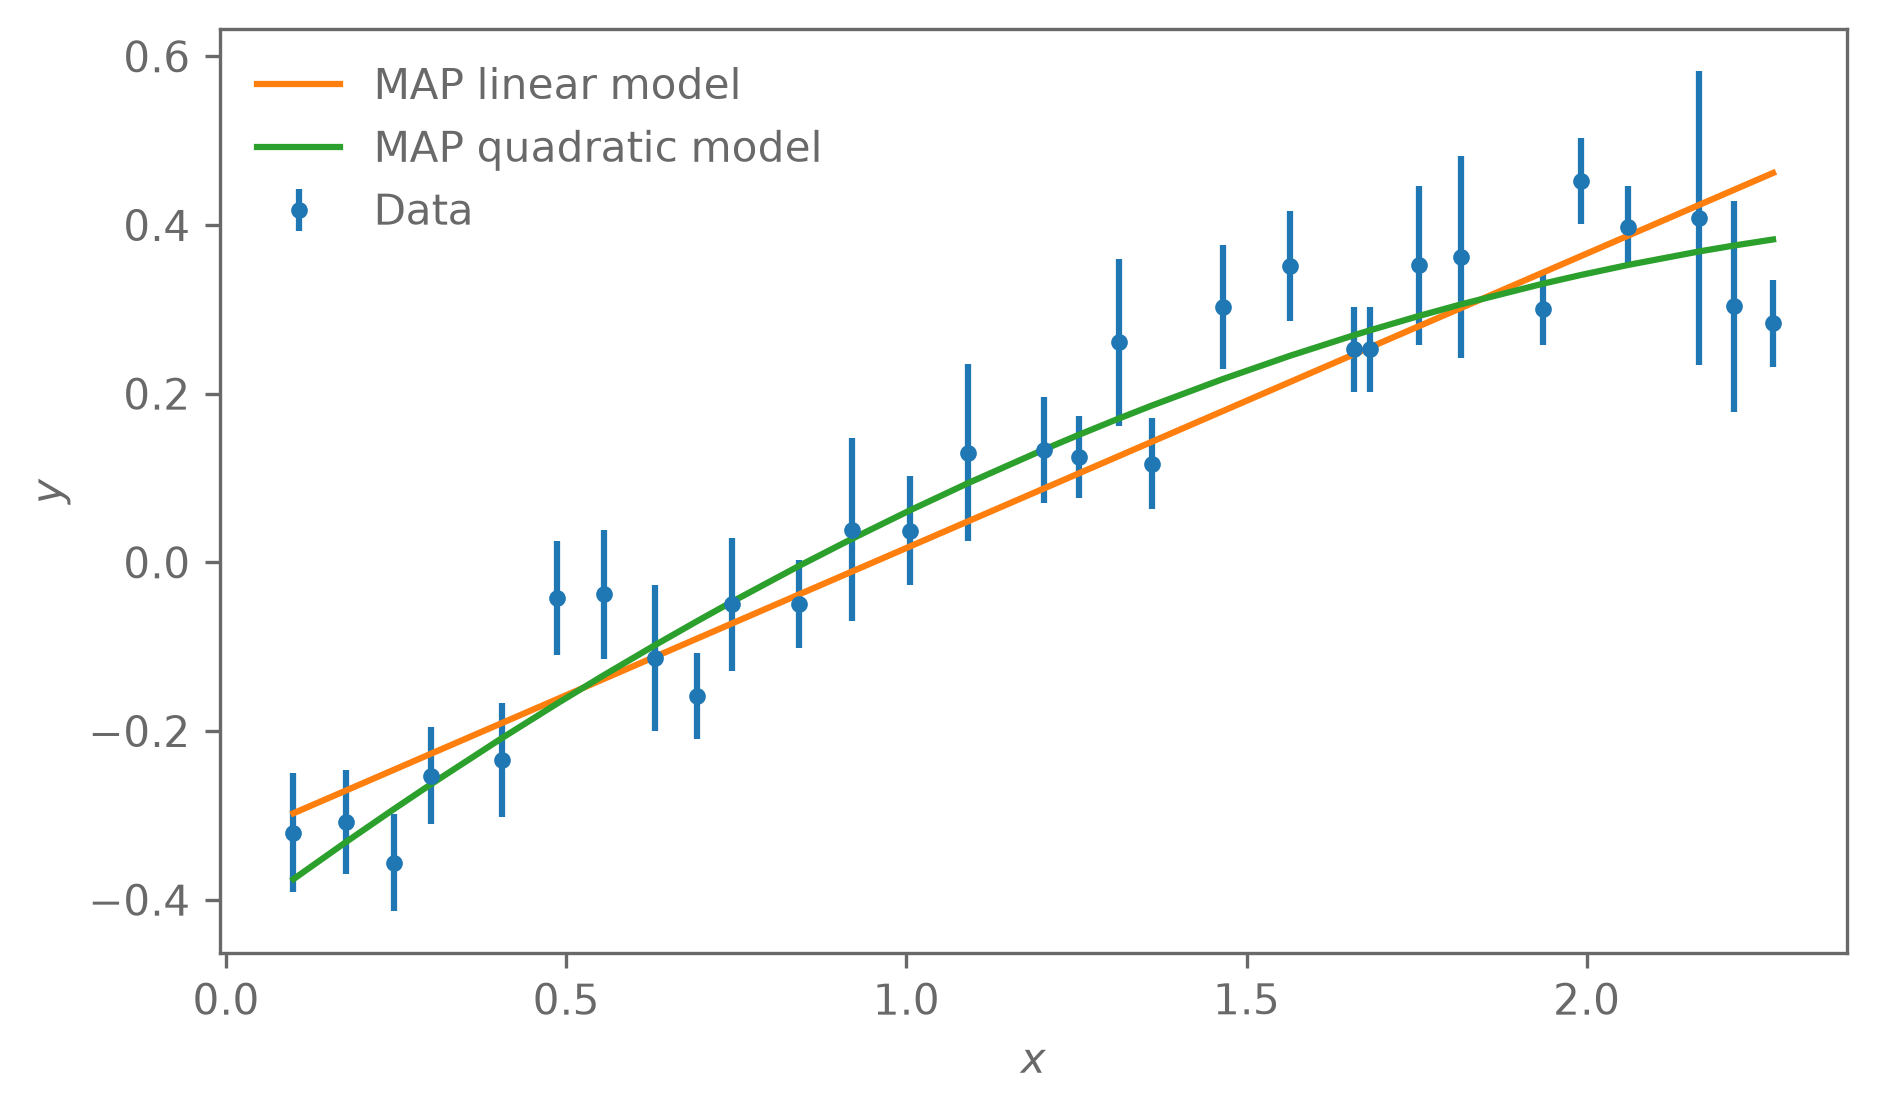

In [42]:
plot_data(
    x, y, y_err,
    models=[
        dict(x=x, y=linear_model(results_linear["MAP"], x), style=dict(label="MAP linear model")),
        dict(x=x, y=quadratic_model(results_quadratic["MAP"], x), style=dict(label="MAP quadratic model"))
    ]
);

### calculate $\chi^2$ on MAP parameters

In [43]:
def chi_squared(y, sigma_y, mu):
    return np.sum((y - mu)**2/sigma_y**2)

chi_squared_linear = chi_squared(
    y, y_err,
    mu=linear_model(results_linear["MAP"], x)
)
chi_squared_quadratic = chi_squared(
    y, y_err,
    mu=quadratic_model(results_quadratic["MAP"], x)
)

In [44]:
n_data = len(y)
n_param_lin = 2
n_param_quad = 3

PTE_lin = scipy.stats.chi2(df=n_data - n_param_lin).sf(chi_squared_linear)
PTE_quad = scipy.stats.chi2(df=n_data - n_param_quad).sf(chi_squared_quadratic)

print(f"Linear: χ²={chi_squared_linear:.1f}, "
      f"ndof={n_data}-{n_param_lin}, PTE={PTE_lin:.3f}")

print(f"Quadratic: χ²={chi_squared_quadratic:.1f}, "
      f"ndof={n_data}-{n_param_quad}, PTE={PTE_quad:.3f}")

Linear: χ²=40.8, ndof=30-2, PTE=0.056
Quadratic: χ²=29.3, ndof=30-3, PTE=0.347


### What about when we have posteriors?

## Exercise 3 -- Posterior predictive p-value problems

### **Calculate $p_B$ from the lecture notes now using our posteriors.** 

`results_quad` contains posterior predictive draws already in it. You can use these if you'd like. These represent a list of draws from $p(y | \theta^s)$ where $s$ represents the step in the chain. 

To help with some conventions from results from earlier in the notebook:

If you have run the notebook to this point, then you can use `results_linear['chain']` to get values of $\theta$, `predict_lin` or `predict_quad` to draw from the posterior predictive, `linear_model` or `quadratic_model` to calculate the **model** predictive (needed for the $\chi^2$). 

### **Try another statistic**: how many times does the sign of the residual change? If we fit a line to quadratic data, then we'd expect there to be a chunk of residuals that are all positive, in a row, for example. 

In [ ]:
#results_quadratic
n_draws = 500
random_draw_integers = np.random.randint()

for ii in range(n_draws):
    theta_S = results_linear["chain"][random_draw_integers[ii]]
    y_rep_S = predict_lin(theta_S,x,y_err)

TypeError: make_gaussian_likelihood_components.<locals>.predict() missing 2 required positional arguments: 'x' and 'sigma_y'

In [53]:
results_quadratic["chain"]

array([[-0.09895345,  0.60450134, -0.43116727],
       [-0.13705328,  0.68218287, -0.46489996],
       [-0.12354763,  0.64414066, -0.45110304],
       ...,
       [-0.07620671,  0.53035594, -0.4097235 ],
       [-0.09206272,  0.55404152, -0.38688484],
       [-0.09530974,  0.57694453, -0.42590947]], shape=(927, 3))